In this notebook, we will train an RCM emulator from scratch using PyTorch and the CORDEX Benchmark dataset (for more information on the data, see the notebooks in [`../data`](../data/)).

The workflow is as follows:

- Train the RCM emulator under one of the two training configurations available.
- Evaluate it on a subset of the same RCM simulations used for training.

We have kept the set of dependencies minimal. For further details, see the [README](../README.md#requirements).

In [5]:
from pathlib import Path
import yaml
import xarray as xr
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [6]:
# Load experiment settings
with open('../benchmark/experiments.yaml', 'r') as f:
    experiments = yaml.safe_load(f)

# Load mapping horizons to periods
with open('../benchmark/horizons.yaml', 'r') as f:
    horizons = yaml.safe_load(f)

# Load RCM/GCM by domain and train/test setup
with open('../benchmark/datasets.yaml', 'r') as f:
    datasets = yaml.safe_load(f)

First, we define two functions to facilitate plotting of the generated data, including the Power Spectral Density (PSD), which will be used to evaluate the RCM emulator.

In [2]:
def plot_data_map(data, var_name, domain, vmin, vmax,
                  fig_title='', figsize=(8,8), cmap='viridis'):
    
    central_longitude = 180 if domain == 'NZ' else 0 if domain == 'ALPS' else None
    
    plt.figure(figsize=figsize)
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=central_longitude))

    if (domain == 'NZ') or (domain == 'SA'):
        data[var_name].plot(ax=ax, transform=ccrs.PlateCarree(),
                            vmin=vmin, vmax=vmax,
                            cmap=cmap)
    elif domain == 'ALPS':
        cs = ax.pcolormesh(data[var_name]['lon'], data[var_name]['lat'],
                           data[var_name],
                           transform=ccrs.PlateCarree(),
                           vmin=vmin, vmax=vmax,
                           cmap=cmap)
    
    ax.coastlines(resolution='10m')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    
    plt.title(fig_title)
    plt.show()

def plot_psd(psd_target, psd_pred):
    plt.loglog(psd_target.wavenumber, psd_target, label="Target")
    plt.loglog(psd_pred.wavenumber, psd_pred, label="Prediction")
    plt.xlabel("Wavenumber")
    plt.title("Power Spectral Density")
    plt.legend()
    plt.show()

## Configuration

We define the PATHs for the data (which must match those used when downloading the benchmark dataset) and for saving the models.

In [3]:
DATA_PATH = Path('../data/Bench-data')

MODELS_PATH = Path('./models')
MODELS_PATH.mkdir(exist_ok=True)

For this example, we select the `SA` domain. (The code, as written, is also valid for the `ALPS` and `NZ` domains.)

In [4]:
DOMAIN = 'SA'
TRAINING_EXPERIMENT = 'ESD_pseudo_reality'

In [9]:
# Set the period
if TRAINING_EXPERIMENT in experiments:
    train_period = experiments[TRAINING_EXPERIMENT]['train_period']
    if isinstance(train_period, list):
        train_period = '_'.join(train_period)
else:
    raise ValueError('Provide a valid training experiment')

# Set the GCM
if DOMAIN in datasets:
    gcm_name = datasets[DOMAIN]['train_gcm']
else:
    raise ValueError('Provide a valid domain')

## Data


In [10]:
# define paths
train_path = DATA_PATH / f'{DOMAIN}_domain' / 'train' / TRAINING_EXPERIMENT


### Predictors

We load the predictors. For more details on the properties of this dataset (and the predictand), see [`experiments.ipynb`](../data/experiments.ipynb).

In [11]:
predictor_filename = train_path / 'predictors' / f'{gcm_name}_{train_period}.nc'
if predictor_filename.is_file():
    predictor = xr.open_dataset(predictor_filename)
    if DOMAIN == 'SA':
        predictor = predictor.drop_vars('time_bnds')
else:
    raise FileExistsError(f'Predictor file not found: {predictor_filename}')

getfattr: /home/casadoj/Git/ml-benchmark/data/Bench-data/SA_domain/train/ESD_pseudo_reality/predictors/ACCESS-CM2_1961-1980.nc: Operation not supported


### Predictand

As predictands, the benchmark provides both daily maximum temperature (`tasmax`) and daily accumulated precipitation (`pr`). For this tutorial, we focus on maximum temperature.

In [12]:
VAR_TARGET = 'tasmax'

predictand_filename = train_path / 'target' / f'pr_tasmax_{gcm_name}_{train_period}.nc'
if predictand_filename.is_file():
    predictand = xr.open_dataset(predictand_filename)
    predictand = predictand[[VAR_TARGET]]
else:
    raise FileExistsError(f'Predictand file not found: {predictand_filename}')

getfattr: /home/casadoj/Git/ml-benchmark/data/Bench-data/SA_domain/train/ESD_pseudo_reality/target/pr_tasmax_ACCESS-CM2_1961-1980.nc: Operation not supported


### Train-test split

Unfortunately, the benchmark does not yet provide ground-truth data (target RCM simulations) for the evaluation experiments. Therefore, to get an initial sense of the trained DL emulator’ performance, we generate a test set from the data used for training. Evaluating on this test set provides an indication of how well the emulator is performing.

In [13]:
if TRAINING_EXPERIMENT == 'ESD_pseudo_reality':
    years_train = list(range(1961, 1975))
    years_test = list(range(1975, 1980+1))
elif TRAINING_EXPERIMENT == 'Emulator_hist_fut':
    years_train = list(range(1961, 1980+1)) + list(range(2080, 2090))
    years_test = list(range(2090, 2099+1))

x_train = predictor.sel(time=np.isin(predictor['time'].dt.year, years_train))
y_train = predictand.sel(time=np.isin(predictand['time'].dt.year, years_train))

x_test = predictor.sel(time=np.isin(predictor['time'].dt.year, years_test))
y_test = predictand.sel(time=np.isin(predictand['time'].dt.year, years_test))

As it is typical in the DL community, we standardize the training predictors to have a mean of zero and a standard deviation of one. Importantly, the test predictors are standardized using the mean and standard deviation from the training set. This approach ensures that the input data scale remains consistent.

In [14]:
mean_train = x_train.mean('time')
std_train = x_train.std('time')

x_train_stand = (x_train - mean_train) / std_train
x_test_stand = (x_test - mean_train) / std_train

In this tutorial, we train a DL model with a final fully connected layer, so the model output is a flattened vector (which we will later reshape to its original 2D dimensions). Therefore, the target data must also be flattened for training.

In [15]:
if DOMAIN == 'ALPS':
    spatial_dims = ('y', 'x')
elif (DOMAIN == 'NZ') or (DOMAIN == 'SA'):
    spatial_dims = ('lat', 'lon')

y_train_stack = y_train.stack(gridpoint=spatial_dims)
y_test_stack = y_test.stack(gridpoint=spatial_dims)

Finally, we extract the raw data from the `xarray.Dataset` as a NumPy array and convert it to a PyTorch tensor.

In [16]:
x_train_stand_array = torch.from_numpy(x_train_stand.to_array().transpose("time", "variable", "lat", "lon").values)
y_train_stack_array = torch.from_numpy(y_train_stack.to_array()[0, :].values)

x_test_stand_array = torch.from_numpy(x_test_stand.to_array().transpose("time", "variable", "lat", "lon").values)

We define two separate `Dataset` objects: one for training (outputting both inputs and targets) and one for making predictions (outputting only the inputs).

In [17]:
class EmulationTrainingDataset(Dataset):
    def __init__(self, x_data, y_data):
        if not isinstance(x_data, torch.Tensor):
            x_data = torch.tensor(x_data)
        if not isinstance(y_data, torch.Tensor):
            y_data = torch.tensor(y_data)
        self.x_data, self.y_data = x_data, y_data

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x_sample, y_sample = self.x_data[idx, :], self.y_data[idx, :]
        return x_sample, y_sample

class EmulationTestDataset(Dataset):
    def __init__(self, x_data):
        if not isinstance(x_data, torch.Tensor):
            x_data = torch.tensor(x_data)
        self.x_data = x_data

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        return self.x_data[idx, :]

We set the `Dataset` and `DataLoader` for both training and test samples.

In [18]:
# training dataset
dataset_training = EmulationTrainingDataset(
    x_data=x_train_stand_array, 
    y_data=y_train_stack_array
)
dataloader_train = DataLoader(
    dataset=dataset_training,
    batch_size=32, 
    shuffle=True
)

# test dataset
dataset_test = EmulationTestDataset(
    x_data=x_test_stand_array)
test_dataloader = DataLoader(
    dataset=dataset_test,
    batch_size=32, 
    shuffle=False
)

## Model

Now we define the DL architecture to use as our RCM emulator. In this example, we use DeepESD <a id="ref1" href="#footnote1">[1]</a>, a model previously applied for both observational statistical downscaling and RCM emulation <a id="ref2" href="#footnote2">[2]</a>. The architecture consists of three convolutional layers followed by a final dense layer. Despite its simplicity, DeepESD has demonstrated strong performance and has been successfully applied across various domains.

In [19]:
class DeepESD(torch.nn.Module):

    def __init__(self, x_shape: tuple, y_shape: tuple,
                 filters_last_conv: int):

        super(DeepESD, self).__init__()

        self.x_shape = x_shape
        self.y_shape = y_shape
        self.filters_last_conv = filters_last_conv

        self.conv_1 = torch.nn.Conv2d(in_channels=self.x_shape[1],
                                      out_channels=50,
                                      kernel_size=3,
                                      padding=1)

        self.conv_2 = torch.nn.Conv2d(in_channels=50,
                                      out_channels=25,
                                      kernel_size=3,
                                      padding=1)

        self.conv_3 = torch.nn.Conv2d(in_channels=25,
                                      out_channels=self.filters_last_conv,
                                      kernel_size=3,
                                      padding=1)

        self.out = torch.nn.Linear(in_features=\
                                       self.x_shape[2] * self.x_shape[3] * self.filters_last_conv,
                                       out_features=self.y_shape[1])

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        x = self.conv_1(x)
        x = torch.relu(x)

        x = self.conv_2(x)
        x = torch.relu(x)

        x = self.conv_3(x)
        x = torch.relu(x)

        x = torch.flatten(x, start_dim=1)

        out = self.out(x)

        return out

In [20]:
model = DeepESD(x_shape=x_train_stand_array.shape,
                y_shape=y_train_stack_array.shape,
                filters_last_conv=1)
print(model)

DeepESD(
  (conv_1): Conv2d(15, 50, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_2): Conv2d(50, 25, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_3): Conv2d(25, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (out): Linear(in_features=256, out_features=16384, bias=True)
)


## Training

We use the Mean Squared Error (MSE) as the loss function, which is commonly employed for temperature-related tasks. If working with precipitation instead, we recommend exploring alternative loss functions, since MSE is not well-suited for learning distributions with strong skewness, such as precipitation. For further details, see <a id="ref3" href="#footnote3">[3]</a>.

In [21]:
loss_function = nn.MSELoss()

We set the hyperparameters that control how the model weights are learned and select the available device for training.

In [22]:
learning_rate = 0.0001
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

num_epochs = 500

device = ('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

Below, we define the `for` loop to train the model. While there are simpler ways to train DL models within the PyTorch ecosystem, this implementation is useful to gain a clear understanding of the entire training process.

In [24]:
# Initialize a list to store the loss per epoch
loss_train = []

# Iterate over the epochs
for epoch in range(num_epochs):
    # Define a variable to accumulate the cost function value per epoch
    epoch_loss = 0.0 
    
    # Iterate over the batches
    for idx, (batch_x_data, batch_y_data) in enumerate(dataloader_train):
        batch_size = batch_x_data.shape[0]

        # Move data to the device
        batch_x_data = batch_x_data.to(device)
        batch_y_data = batch_y_data.to(device)
        
        # Zero the gradients since by default they accumulate
        optimizer.zero_grad()

        # Compute the forward pass
        outputs = model(batch_x_data)  # PyTorch calls model.forward() internally

        # Compute the cost function
        loss_batch = loss_function(outputs, batch_y_data)
        epoch_loss += batch_size * loss_batch.item()

        # Compute the gradients (backward pass)
        loss_batch.backward()

        # Update the model weights
        optimizer.step()

    # Calculate the loss for the epoch
    epoch_loss = epoch_loss / len(dataset_training)
    loss_train.append(epoch_loss)
    
    # Print every 10 epochs
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f'Epoch {epoch+1}/{num_epochs} - Loss: {epoch_loss:.6f}')

# At the end of training, save the model weights
model_name = f'DeepESD_{TRAINING_EXPERIMENT}_{DOMAIN}_{VAR_TARGET}.pt'
torch.save(model.state_dict(), f'{MODELS_PATH}/{model_name}')

Epoch 1/500 - Loss: 70838.822743
Epoch 10/500 - Loss: 1326.144623
Epoch 20/500 - Loss: 356.680811
Epoch 30/500 - Loss: 164.035481
Epoch 40/500 - Loss: 80.753992
Epoch 50/500 - Loss: 44.211567
Epoch 60/500 - Loss: 28.619829
Epoch 70/500 - Loss: 20.659123
Epoch 80/500 - Loss: 16.505934
Epoch 90/500 - Loss: 13.362599
Epoch 100/500 - Loss: 11.462913
Epoch 110/500 - Loss: 9.706007
Epoch 120/500 - Loss: 8.897273
Epoch 130/500 - Loss: 7.745391
Epoch 140/500 - Loss: 7.858061
Epoch 150/500 - Loss: 6.802939
Epoch 160/500 - Loss: 6.457590
Epoch 170/500 - Loss: 6.044705
Epoch 180/500 - Loss: 6.079049
Epoch 190/500 - Loss: 5.514537
Epoch 200/500 - Loss: 5.070055
Epoch 210/500 - Loss: 5.072029
Epoch 220/500 - Loss: 4.885885
Epoch 230/500 - Loss: 5.066140
Epoch 240/500 - Loss: 4.701099
Epoch 250/500 - Loss: 4.607483
Epoch 260/500 - Loss: 4.391866
Epoch 270/500 - Loss: 4.366976
Epoch 280/500 - Loss: 4.477308
Epoch 290/500 - Loss: 4.277886
Epoch 300/500 - Loss: 4.015652
Epoch 310/500 - Loss: 4.115121
E

## Evaluation

Once the model is trained, we can compute predictions on the test set defined at the beginning of the notebook. To do this, we created a `DataLoader` for the test data and now we pass it through the trained model, obtaining predictions for the entire test set.

In [25]:
# Compute predictions
model.eval()

predictions = []
with torch.no_grad():
    for batch_x in test_dataloader:
        batch_x = batch_x.to(next(model.parameters()).device)
        outputs = model(batch_x)
        predictions.append(outputs.cpu().numpy())

# Concatenate all batches into one array
predictions = np.concatenate(predictions, axis=0)
print("Dimensions\t{{'time': {0}, 'gridpoints': {1}}}".format(*predictions.shape))

Dimensions	{'time': 2190, 'gridpoints': 16384}


The DeepESD model outputs a flattened version of the RCM simulations, so we need to reshape it back to 2D. This is done in the following cell.

In [26]:
y_pred_stack = y_test_stack.copy(deep=True)
y_pred_stack[VAR_TARGET].values = predictions
y_pred = y_pred_stack.unstack()
print(y_pred.dims)

FrozenMappingWarningOnValuesAccess({'lat': 128, 'lon': 128, 'time': 2190})


### Evaluation metrics

Once the predictions for the test set have been computed, we can evaluate them using several metrics. Specifically, we compute the following metrics:

- Root Mean Squared Error (RMSE).
- Bias of the mean.
- Bias of the 98th percentile.
- Ratio of standard deviations.
- Power Spectral Density (PSD).

The implementations of these metrics can be found in the repository [`ml-evaluation`](https://github.com/c3s-cordex-ml/ml-evaluation/).

In [29]:
import ml_evaluation.evaluation.indices as indices
import ml_evaluation.evaluation.diagnostics as diagnostics

Mean RMSE: 1.8644894361495972


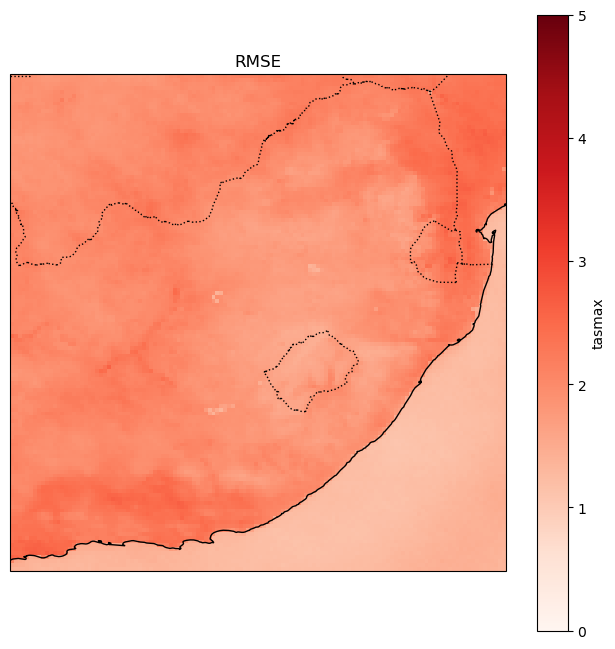

In [ ]:
rmse = diagnostics.rmse_index(
    x0=y_test,
    x1=y_pred,
    var=VAR_TARGET,
    dim='time'
)
print(f'Mean RMSE: {rmse[VAR_TARGET].mean().values.item()}')

plot_data_map(
    data=rmse, 
    var_name=VAR_TARGET, 
    domain=DOMAIN, 
    vmin=0, vmax=5, cmap='Reds',
    fig_title='RMSE'
)

Mean Bias Mean: 0.5023346543312073


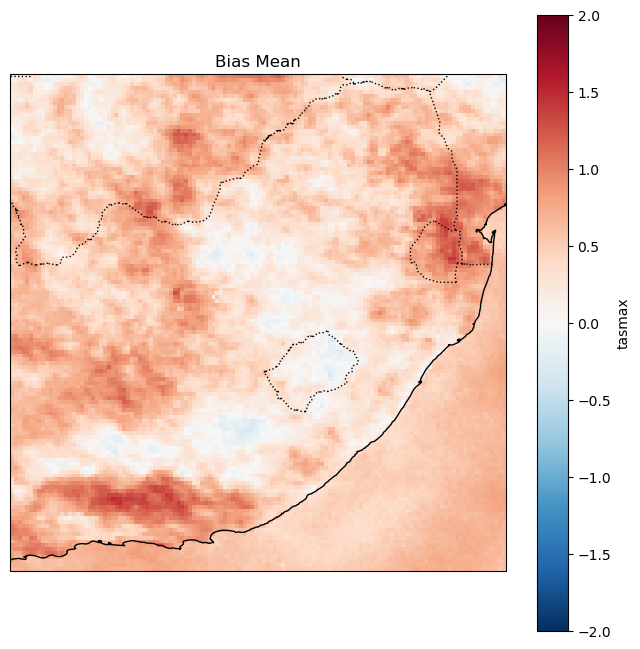

In [31]:
bias_mean = diagnostics.bias_index(
    x0=y_test,
    x1=y_pred,
    index_fn=indices.mean,
    var=VAR_TARGET
)
print(f'Mean Bias Mean: {bias_mean[VAR_TARGET].mean().values.item()}')

plot_data_map(
    data=bias_mean, 
    var_name=VAR_TARGET, 
    domain=DOMAIN, 
    vmin=-2, vmax=2, cmap='RdBu_r',
    fig_title='Bias Mean'
)

Mean Bias 98th percentile: 0.04167607732117172


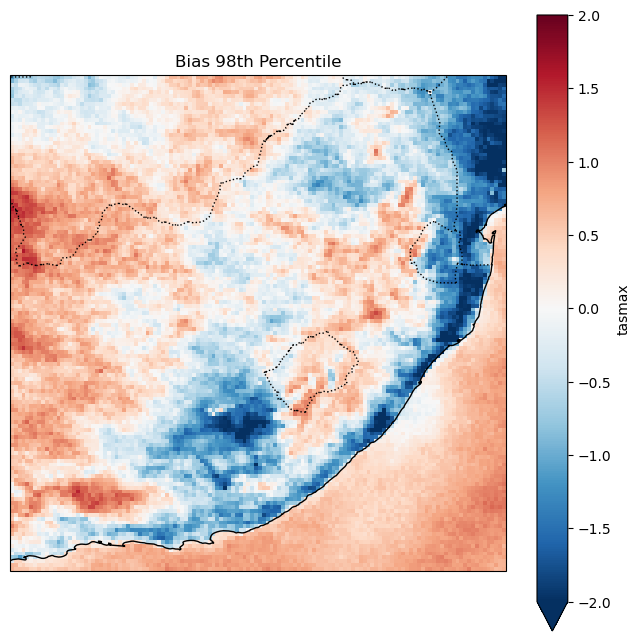

In [32]:
bias_p98 = diagnostics.bias_index(
    x0=y_test,
    x1=y_pred,
    index_fn=indices.season_quantile,
    q=0.98,
    var=VAR_TARGET
)

print(f'Mean Bias 98th percentile: {bias_p98[VAR_TARGET].mean().values.item()}')

plot_data_map(
    data=bias_p98, 
    var_name=VAR_TARGET, 
    domain=DOMAIN, 
    vmin=-2, vmax=2, cmap='RdBu_r',
    fig_title='Bias 98th Percentile'
)

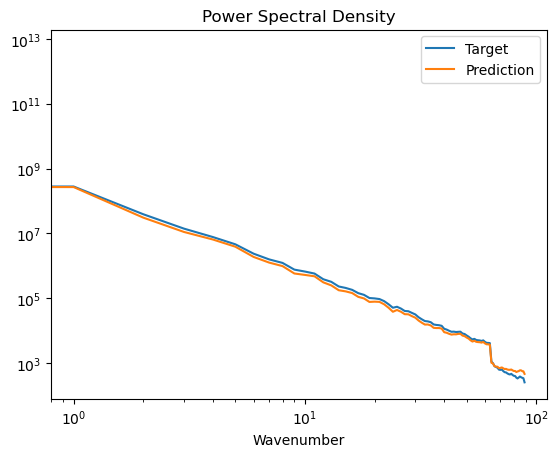

In [33]:
psd_target, psd_pred = diagnostics.psd(
    x0=y_test, 
    x1=y_pred,
    var=VAR_TARGET
)

plot_psd(psd_target=psd_target[VAR_TARGET], psd_pred=psd_pred[VAR_TARGET])

For visualization purposes, we also plot the RCM simulation alongside the emulator’s prediction for a specific day.

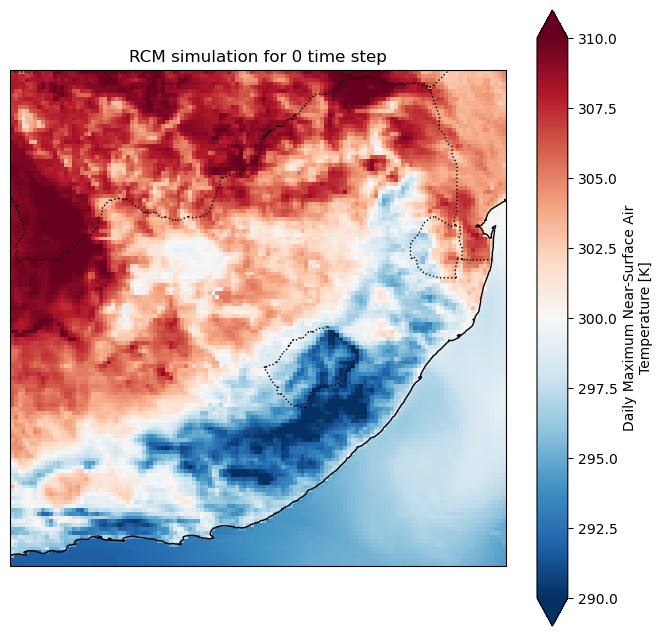

In [34]:
time_idx = 0

plot_data_map(
    data=y_test.isel(time=time_idx), 
    var_name=VAR_TARGET, 
    domain=DOMAIN,
    vmin=290, vmax=310, cmap='RdBu_r',
    fig_title=f'RCM simulation for {time_idx} time step', 
    figsize=(8,8)
)

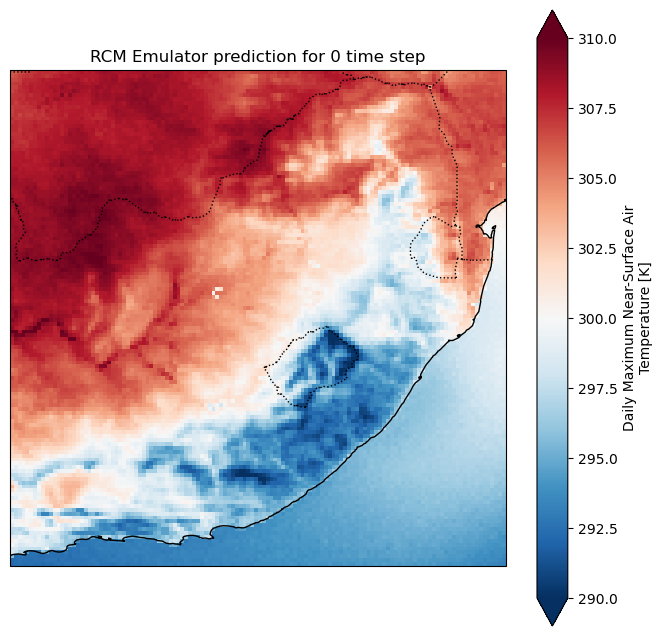

In [35]:
plot_data_map(
    data=y_pred.isel(time=0), 
    var_name=VAR_TARGET, 
    domain=DOMAIN,
    vmin=290, vmax=310, cmap='RdBu_r',
    fig_title=f'RCM Emulator prediction for {time_idx} time step', 
    figsize=(8,8)
)

**References**

<p id="footnote1">[1] Baño-Medina, J., Manzanas, R., Cimadevilla, E., Fernández, J., González-Abad, J., Cofiño, A. S., & Gutiérrez, J. M. (2022). **Downscaling multi-model climate projection ensembles with deep learning (DeepESD): contribution to CORDEX EUR-44**. Geoscientific Model Development Discussions, 2022, 1-14.<a href="#ref1">↩</a></p>

<p id="footnote2">[2] Baño-Medina, J., Iturbide, M., Fernández, J., & Gutiérrez, J. M. (2024). **Transferability and explainability of deep learning emulators for regional climate model projections: Perspectives for future applications**. Artificial Intelligence for the Earth Systems, 3(4), e230099.<a href="#ref2">↩</a></p>

<p id="footnote3">[3] González-Abad, J., & Gutiérrez, J. M. (2025). **Are Deep Learning Methods Suitable for Downscaling Global Climate Projections? An Intercomparison for Temperature and Precipitation over Spain**. Artificial Intelligence for the Earth Systems, 4(4), 240121.<a href="#ref2">↩</a></p>